# Q1C | Analyze Relationships Between Attributes

> C. Analyze the relationships between the data attributes, and between the data attributes and label. This involves computing the Pearson Correlation Coefficient (PCC) and generating scatter plots.

**IMPORTANT**

This notebook uses only the train dataset, so no analysis or treatment decision is influenced by the test data (data snooping). Every statistic below is computed on the training rows only.

# Answer Summary

**PCC and scatter plots**
- A scatter matrix of every pair of the 9 columns, a correlation matrix with Pearson r (lower triangle) next to Spearman rho (upper triangle), a collinearity table of the attribute pairs with r of 0.3 or more in size next to each one's r with `Life Ladder`, and an R² gain table for the pairs of attributes that gain 0.01 or more (what the weaker attribute of each pair adds to a linear fit of `Life Ladder`).

**Attributes and label**
- Strength: strong for `Log GDP per capita`, `Healthy life expectancy at birth` and `Social support`, led by `Log GDP per capita` (r 0.79). Moderate for `Freedom to make life choices`, `Positive affect` and `Perceptions of corruption`. Weak for `Negative affect` and `Generosity`, `Generosity` the weakest.
- Direction: `Perceptions of corruption` and `Negative affect` are the only attributes that fall as `Life Ladder` rises.
- Shape: `Social support` and `Healthy life expectancy at birth` are shallow, then steep, so their rank correlation is higher than their straight line one (`Social support`: Spearman 0.75 against Pearson 0.70).
- Thin tail: `Perceptions of corruption` is the reverse. Its link sits in a thin low tail, so Pearson is stronger than Spearman (-0.43 against -0.32).

**Attribute vs attribute**
- One near-duplicate pair: `Log GDP per capita` and `Healthy life expectancy at birth` (r 0.851) carry largely the same information.
- Two clusters: `Log GDP per capita`, `Healthy life expectancy at birth` and `Social support` correlate 0.62 to 0.85 with each other, and `Freedom to make life choices` and `Positive affect` form a second, looser pair.
- Weakly linked attributes add the most: `Positive affect`, only weakly linked to `Log GDP per capita`, adds more to it than any other attribute (+0.098).
- Overlap erases weak attributes: only 4 of the 28 pairs are left out of the pairs table, and all 4 hold `Negative affect` or `Generosity` next to an attribute they correlate with, ex `Negative affect` with `Social support`.

**Carried to D**
- Keep both `Log GDP per capita` and `Healthy life expectancy at birth`: although they are the near-duplicate pair, `Healthy life expectancy at birth` still adds more than the 0.01 bar on top of `Log GDP per capita` (+0.023 in the pairs table).

---

# Imports

In [1]:
import pandas as pd

import Q1.consts as Q1_CONSTS
from consts import COLLINEARITY_MIN_R, R2_GAIN_MARGIN

from utils import (
	read_csv_to_df,
	STATISTICS,
	PLOTTING,
)

pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)

# Fetch Data

In [2]:
train_df = read_csv_to_df(path=Q1_CONSTS.TRAIN_PATH)

# Attribute vs Attribute & Label

## Scatter Matrix

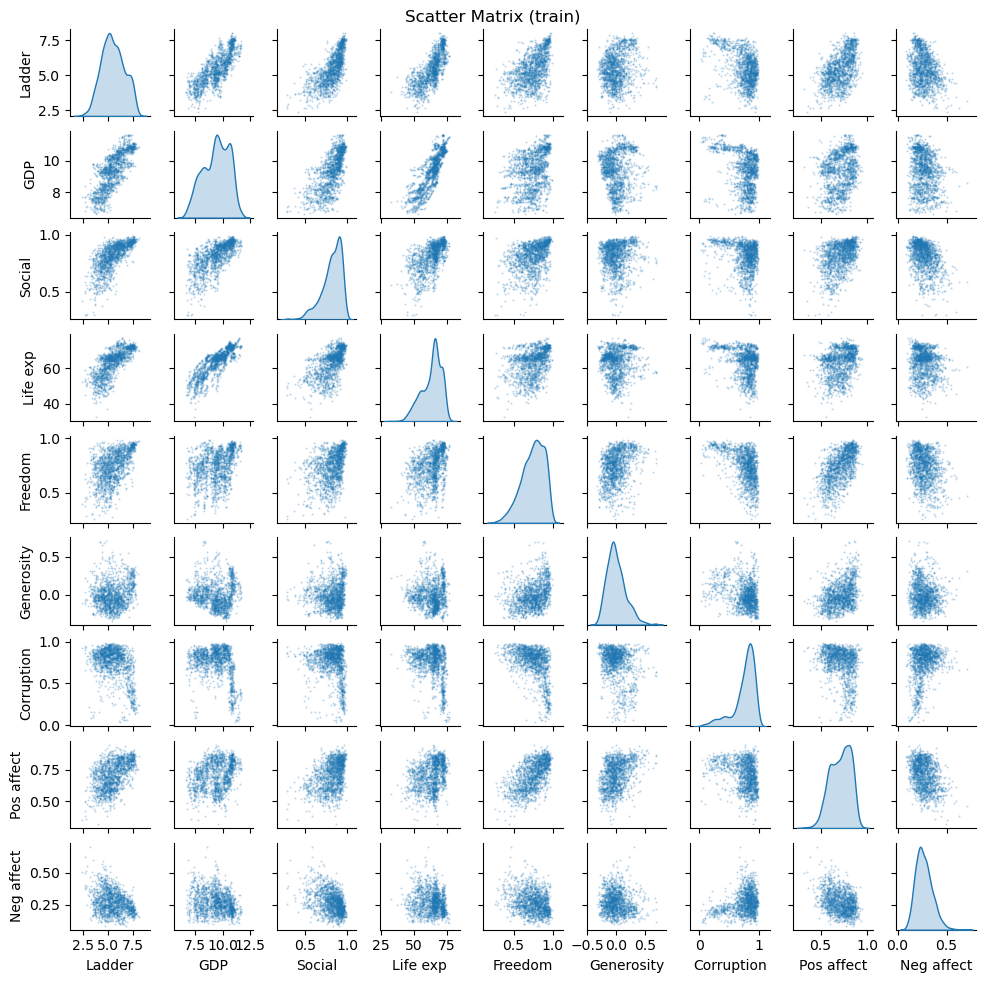

In [3]:
PLOTTING.scatter_matrix(df=train_df, labels=Q1_CONSTS.SHORT_NAMES, title='Scatter Matrix (train)');

### Notes / Observations

- Strongest trends with the label: `Life Ladder` rises in a narrow band with `Log GDP per capita`, `Healthy life expectancy at birth` and `Social support`, in looser clouds with `Freedom to make life choices` and `Positive affect`, falls with `Perceptions of corruption` and `Negative affect`, and shows no clear trend with `Generosity`.
- Bends, not lines: `Social support` and `Healthy life expectancy at birth` are shallow at the low end and steep at the top against `Life Ladder`, the bend measured in B, so a straight line understates how closely they move with the label.
- Tightest attribute pair: `Log GDP per capita` against `Healthy life expectancy at birth` is a narrow rising band close to a line, so the two attributes order the rows almost the same way.
- `Perceptions of corruption` is an L shape: most rows pile up between about 0.7 and 1 at every level of the other attributes, and low values appear only in a thin tail where `Life Ladder`, `Log GDP per capita` and `Healthy life expectancy at birth` are high. The relationship lives in that tail, not in the dense cluster.
- `Generosity` is a flat cloud against `Log GDP per capita`, `Social support` and `Healthy life expectancy at birth`, but rises with `Freedom to make life choices` and `Positive affect`, which also rise together in the clearest trend outside the strong three.

## Correlation

> How To Read

- **Strength bands** used in the notes, by the size of r (sign ignored), following Schober, Boer and Schwarte (2018): strong 0.7 or more, moderate 0.4 to 0.7, weak 0.1 to 0.4, none below 0.1.

<Axes: title={'center': 'Pearson (lower) vs Spearman (upper) Correlation Matrix (train)'}>

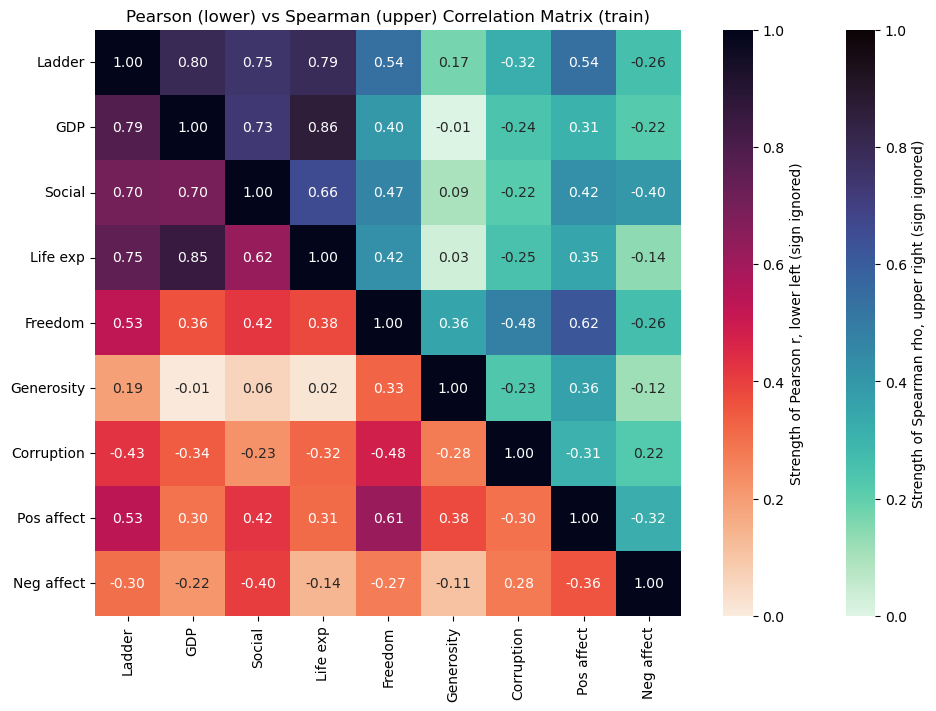

In [4]:
PLOTTING.correlation_matrix(
	pearson=train_df.corr(),
	spearman=train_df.corr(method='spearman'),
	labels=Q1_CONSTS.SHORT_NAMES,
	title='Pearson (lower) vs Spearman (upper) Correlation Matrix (train)',
)

### Notes / Observations

- Strength with the label: `Log GDP per capita`, `Healthy life expectancy at birth` and `Social support` are strong, led by `Log GDP per capita` (r 0.79). `Freedom to make life choices` and `Positive affect` are moderate, and `Generosity` is weak. `Perceptions of corruption` and `Negative affect` are the only negative ones.
- The strong three also correlate with each other (0.62 to 0.85), most of all `Log GDP per capita` and `Healthy life expectancy at birth` (0.85). A high r with the label does not mean each one adds its own information (R2 Gain below).
- Spearman above Pearson on the bends: Pearson and Spearman are close on most cells, but `Social support` (0.70 against 0.75) and `Healthy life expectancy at birth` rank `Life Ladder` better than a straight line fits it, which matches their shallow, then steep scatter.
- Pearson above Spearman on `Perceptions of corruption`: -0.43 against -0.32 with `Life Ladder`, and Pearson is stronger with `Log GDP per capita` too. The thin low tail drives the straight line fit, while ranks give it no extra weight and the dense cluster near the top shows little trend.
- `Generosity` stands apart: no linear relationship with `Log GDP per capita`, `Social support` and `Healthy life expectancy at birth` (-0.01 to 0.06), but it correlates with `Positive affect` and `Freedom to make life choices`, both pairs in the collinearity table.

## Collinearity

> How To Read

- **Rows:** one per pair of attributes, sorted by the size of the r between them, largest first. `Life Ladder` never forms a pair.
- **r between attributes:** the Pearson r of the two attributes with each other. Near 1 or -1, the two move together, so a linear model has trouble splitting the credit between them.
- **r with target, first / second:** each attribute's Pearson r with `Life Ladder`, in the order the pair is named. In a strongly correlated pair, it shows which of the two tracks `Life Ladder` more closely.
- Each r uses the train rows where both of its columns are present.
- **Filter:** only pairs with an r between attributes of 0.3 or more in size are shown (`COLLINEARITY_MIN_R`). Below 0.3 the two share less than 10% of their variation (r²), too little to matter for collinearity. The line above the table counts the pairs left out.

In [5]:
STATISTICS.collinearity_df(df=train_df, target=Q1_CONSTS.TARGET, min_abs_r=COLLINEARITY_MIN_R)

17 of 28 pairs shown: the other 11 have |r between attributes| below 0.3.


,r between attributes,"r with target, first","r with target, second"
Log GDP per capita + Healthy life expectancy at birth,0.851,0.787,0.751
Log GDP per capita + Social support,0.697,0.787,0.704
Social support + Healthy life expectancy at birth,0.621,0.704,0.751
Freedom to make life choices + Positive affect,0.614,0.530,0.535
Freedom to make life choices + Perceptions of corruption,-0.481,0.530,-0.428
Social support + Positive affect,0.425,0.704,0.535
Social support + Freedom to make life choices,0.420,0.704,0.530
Social support + Negative affect,-0.404,0.704,-0.302
Healthy life expectancy at birth + Freedom to make life choices,0.382,0.751,0.530
Generosity + Positive affect,0.377,0.195,0.535


### R2 Gain

> How To Read

One row per pair of attributes. Each pair is an ordinary linear regression of `Life Ladder` on its two attributes, fit on the train rows where both of them and `Life Ladder` are present.

- **r2 together:** the R² of the fit on both attributes of the pair.
- **r2 best with one left out:** the higher R² of the two fits on one attribute alone.
- **r2 gain:** r2 together minus r2 best with one left out, so what the weaker attribute adds on top of the other. Rows are sorted by it, largest first.
- A gain near 0 means the attribute's information is already in the other one, even when its own r with `Life Ladder` is high. A large gain means it brings information the other one lacks.
- Every R² is scored on the rows it is fit on, so a gain is never below 0 and is a little optimistic. A gain of a few thousandths is not evidence on its own.
- **Filter:** only pairs with a gain of 0.01 or more are shown (`R2_GAIN_MARGIN`, the same bar Q1B uses to draw a candidate shape). The line above the table counts the pairs left out, and a missing pair is one that adds less than 0.01.

In [6]:
STATISTICS.r2_gain_df(df=train_df, target=Q1_CONSTS.TARGET, min_gain=R2_GAIN_MARGIN)  # pairs

24 of 28 pairs shown: the other 4 gain less than 0.01.


,r2 best with one left out,r2 together,r2 gain
Healthy life expectancy at birth + Positive affect,0.567,0.666,0.099
Log GDP per capita + Positive affect,0.620,0.717,0.098
Social support + Healthy life expectancy at birth,0.564,0.657,0.093
Perceptions of corruption + Positive affect,0.287,0.365,0.078
Social support + Perceptions of corruption,0.502,0.577,0.075
Healthy life expectancy at birth + Freedom to make life choices,0.566,0.637,0.072
Log GDP per capita + Freedom to make life choices,0.621,0.689,0.068
Social support + Positive affect,0.496,0.563,0.067
Social support + Freedom to make life choices,0.496,0.562,0.066
Freedom to make life choices + Positive affect,0.290,0.355,0.065


### Notes / Observations

- One near-duplicate pair: `Log GDP per capita` and `Healthy life expectancy at birth` are by far the most correlated pair (r 0.851).
- Little added on top of each other: `Healthy life expectancy at birth` adds only +0.023 to `Log GDP per capita`, although on its own it tracks `Life Ladder` almost as closely. The two carry largely the same information.
- Weakly linked partners add the most: the top pair gains come from adding `Positive affect` to `Healthy life expectancy at birth` or to `Log GDP per capita` (+0.099 and +0.098), two attributes it is only weakly linked to in the correlation matrix.
- Moderate collinearity does not erase a gain: `Social support` still adds +0.093 to `Healthy life expectancy at birth`, the third most correlated pair in the collinearity table.
- Overlap erases weak attributes: the 4 pairs left out of the pairs table are `Negative affect` with `Social support`, and `Generosity` with `Positive affect`, `Freedom to make life choices` and `Perceptions of corruption`, each an attribute it correlates with.
- A partner with no overlap keeps a weak attribute: `Generosity` adds +0.040 next to `Log GDP per capita`, with which it has near zero r in the correlation matrix.